# 00. 로봇용접 제조데이터 EDA — 보고서/PPT용 표 자동 출력

이 노트북은 **원본 Excel만 입력하면 EDA → 표 출력 → CSV/PNG 저장**까지 한 번에 수행

주요 산출물은 `outputs/eda_report/`에 저장됨

- 보고서/PPT용 표 PNG
- 원본 숫자 확인용 CSV
- 일자별 생산량/불량 집계 그림
- 공정변수 상관관계 그림

> 주의: `result` 시트는 **개별 제품 라벨이 아니라 일별/불량유형별 집계**이므로 Raw data와 행 단위로 조인해 불량 라벨을 만들지 않음.


### 1. 경로 설정

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)



DATA_PATH = None  # 필요하면 직접 지정: Path("Welding Data Set_01.xlsx")
OUT_DIR = Path("outputs") / "eda_report"
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR = OUT_DIR / "figures"
for p in [OUT_DIR, TABLE_DIR, FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# 한국어 폰트 자동 선택
font_candidates = ["NanumSquare", "NanumGothic", "Malgun Gothic", "AppleGothic", "DejaVu Sans"]
available = {f.name for f in font_manager.fontManager.ttflist}
for candidate in font_candidates:
    if candidate in available:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams["axes.unicode_minus"] = False

FEATURES = [
    "weld force(bar)",
    "weld current(kA)",
    "weld Voltage(v)",
    "weld time(ms)",
]
FEATURE_KO = {
    "weld force(bar)": "가압력",
    "weld current(kA)": "전류",
    "weld Voltage(v)": "전압",
    "weld time(ms)": "통전시간",
}
UNITS = {
    "weld force(bar)": "bar",
    "weld current(kA)": "kA",
    "weld Voltage(v)": "V",
    "weld time(ms)": "ms",
}
COLLECTION_RANGES = {
    "weld force(bar)": (1.0, 12.0),
    "weld current(kA)": (12.0, 18.0),
    "weld Voltage(v)": (1.5, 3.5),
    "weld time(ms)": (30.0, 120.0),
}

TRAIN_DATES = pd.to_datetime(["2020-03-24", "2020-03-25", "2020-03-26", "2020-03-27"])
VALID_DATES = pd.to_datetime(["2020-03-30", "2020-03-31"])
FOLLOWUP_DATES = pd.to_datetime(["2020-04-02", "2020-04-03", "2020-04-07"])

print("Output directory:", OUT_DIR.resolve())


Output directory: /home/kampuser/project_final/source_code/source_code/outputs/eda_report


### 2. 원본 Excel 자동 탐색 및 로드

In [2]:


def find_input_excel():
    if DATA_PATH is not None:
        path = Path(DATA_PATH)
        if not path.exists():
            raise FileNotFoundError(path)
        return path

    search_roots = [Path("."), Path("data"), Path("/mnt/data")]
    patterns = ["Welding Data Set_01*.xlsx", "*Welding*Data*Set*.xlsx", "*용접*.xlsx"]
    candidates = []
    for root in search_roots:
        if not root.exists():
            continue
        for pattern in patterns:
            candidates.extend(root.glob(pattern))
    candidates = sorted(set(candidates), key=lambda p: ("scaled" in p.name.lower(), len(p.name), p.name))
    if not candidates:
        raise FileNotFoundError("Welding Data Set_01.xlsx를 현재 폴더 또는 data 폴더에 넣어주세요.")
    return candidates[0]

excel_path = find_input_excel()
print("Input:", excel_path.resolve())

raw = pd.read_excel(excel_path, sheet_name="Raw data")
result = pd.read_excel(excel_path, sheet_name="result")
try:
    data_dict = pd.read_excel(excel_path, sheet_name="data set")
except Exception:
    data_dict = pd.DataFrame()

raw.columns = raw.columns.astype(str).str.strip()
result.columns = result.columns.astype(str).str.strip()

raw.insert(0, "source_row", np.arange(1, len(raw) + 1))
raw["working time"] = pd.to_datetime(raw["working time"], errors="raise")
raw["date"] = raw["working time"].dt.normalize()
result["working time"] = pd.to_datetime(result["working time"], errors="raise")
result["date"] = result["working time"].dt.normalize()

for c in FEATURES:
    raw[c] = pd.to_numeric(raw[c], errors="raise")
result["defect"] = pd.to_numeric(result["defect"], errors="raise").astype(int)

print("Raw data:", raw.shape)
print("Result:", result.shape)
display(raw.head())
display(result.head())


Input: /home/kampuser/project_final/source_code/source_code/Welding Data Set_01.xlsx
Raw data: (11939, 12)
Result: (23, 8)


,source_row,idx,Machine_Name,Item No,working time,Thickness 1(mm),Thickness 2(mm),weld force(bar),weld current(kA),weld Voltage(v),weld time(ms),date
0,1,1,Spot-01,65235-25800,2020-03-24,0.7,0.7,2.33,14.57,2.701,72.0,2020-03-24
1,2,2,Spot-01,65235-25800,2020-03-24,0.7,0.7,2.36,14.57,2.701,72.0,2020-03-24
2,3,3,Spot-01,65235-25800,2020-03-24,0.7,0.7,2.37,14.54,2.703,71.0,2020-03-24
3,4,4,Spot-01,65235-25800,2020-03-24,0.7,0.7,2.37,14.54,2.703,72.0,2020-03-24
4,5,5,Spot-01,65235-25800,2020-03-24,0.7,0.7,2.36,14.56,2.704,72.0,2020-03-24


,idx,Machine_Name,Item No,working time,defect,defect type,Unnamed: 6,date
0,1,Spot-01,65235-25800,2020-03-24,2,1,파임불량,2020-03-24
1,2,Spot-01,65235-25800,2020-03-24,1,2,용접부족,2020-03-24
2,3,Spot-01,65235-25800,2020-03-24,1,3,크랙발생,2020-03-24
3,4,Spot-01,65235-25800,2020-03-25,3,1,NaN,2020-03-25
4,5,Spot-01,65235-25800,2020-03-25,2,2,NaN,2020-03-25


## 3. 표/그림 저장 함수 — PPT/보고서 붙여넣기용 PNG

In [3]:


def format_value(v):
    if pd.isna(v):
        return "-"
    if isinstance(v, (np.integer, int)):
        return f"{int(v):,}"
    if isinstance(v, (np.floating, float)):
        if abs(v) >= 1000:
            return f"{v:,.0f}"
        if abs(v) >= 10:
            return f"{v:,.2f}"
        return f"{v:,.3f}"
    if isinstance(v, pd.Timestamp):
        return v.strftime("%Y-%m-%d")
    return str(v)


def save_table(df, filename, title=None, max_rows=30, dpi=220):
    """DataFrame을 CSV + PPT/Word용 PNG로 저장."""
    df_out = df.copy()
    csv_path = TABLE_DIR / f"{filename}.csv"
    png_path = TABLE_DIR / f"{filename}.png"
    df_out.to_csv(csv_path, index=False, encoding="utf-8-sig")

    render = df_out.head(max_rows).copy()
    for c in render.columns:
        render[c] = render[c].map(format_value)

    nrows, ncols = render.shape
    fig_w = max(8, min(18, 2.0 + ncols * 2.0))
    fig_h = max(2.2, 1.4 + nrows * 0.46 + (0.6 if title else 0))
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")
    tbl = ax.table(
        cellText=render.values,
        colLabels=render.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.35)

    header_color = "#1F4E78"
    alt_color = "#F3F6F8"
    edge_color = "#B7C9D6"
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor(edge_color)
        cell.set_linewidth(0.6)
        if r == 0:
            cell.set_facecolor(header_color)
            cell.get_text().set_color("white")
            cell.get_text().set_weight("bold")
        elif r % 2 == 0:
            cell.set_facecolor(alt_color)

    if title:
        ax.set_title(title, fontsize=14, weight="bold", pad=14)
    fig.tight_layout()
    fig.savefig(png_path, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return csv_path, png_path


def show_and_save(df, filename, title):
    display(df)
    csv_path, png_path = save_table(df, filename, title)
    print("saved:", csv_path)
    print("saved:", png_path)


## 4. 데이터 개요

In [4]:
overview = pd.DataFrame([
    ["생산데이터 건수", len(raw), "Raw data 생산기록"],
    ["생산일 수", raw["date"].nunique(), "2020-03-24 ~ 2020-04-07"],
    ["설비 수", raw["Machine_Name"].nunique(), ", ".join(raw["Machine_Name"].astype(str).unique())],
    ["품목 수", raw["Item No"].nunique(), ", ".join(raw["Item No"].astype(str).unique())],
    ["두께 1 고유값", raw["Thickness 1(mm)"].nunique(), str(sorted(raw["Thickness 1(mm)"].unique().tolist()))],
    ["두께 2 고유값", raw["Thickness 2(mm)"].nunique(), str(sorted(raw["Thickness 2(mm)"].unique().tolist()))],
    ["result 집계 행 수", len(result), "일별·불량유형별 집계"],
    ["불량 집계 기록일", result["date"].nunique(), "3/27은 result 미기록"],
    ["기록된 불량 합계", int(result["defect"].sum()), "개별 제품 라벨 아님"],
], columns=["항목", "결과", "해석/비고"])
show_and_save(overview, "table_01_dataset_overview", "표 1. 데이터셋 개요")


,항목,결과,해석/비고
0,생산데이터 건수,11939,Raw data 생산기록
1,생산일 수,9,2020-03-24 ~ 2020-04-07
2,설비 수,1,Spot-01
3,품목 수,1,65235-25800
4,두께 1 고유값,1,[0.7]
5,두께 2 고유값,1,[0.7]
6,result 집계 행 수,23,일별·불량유형별 집계
7,불량 집계 기록일,8,3/27은 result 미기록
8,기록된 불량 합계,39,개별 제품 라벨 아님


saved: outputs/eda_report/tables/table_01_dataset_overview.csv
saved: outputs/eda_report/tables/table_01_dataset_overview.png


## 5. 주요 변수 정의 

In [5]:
variable_table = pd.DataFrame([
    ["idx", "생산순번", "-", "세부 타임스탬프가 없어 생산순서 근사치로 활용"],
    ["Machine_Name", "생산설비", "-", "현재 데이터에서는 1종"],
    ["Item No", "생산품목", "-", "현재 데이터에서는 1종"],
    ["working time", "작업일", "date", "모든 값이 일 단위로 기록"],
    ["Thickness 1(mm)", "소재 두께 1", "mm", "현재 데이터에서는 상수"],
    ["Thickness 2(mm)", "소재 두께 2", "mm", "현재 데이터에서는 상수"],
    ["weld force(bar)", "용접 가압력", "bar", "모델 입력"],
    ["weld current(kA)", "용접 전류", "kA", "모델 입력"],
    ["weld Voltage(v)", "용접 전압", "V", "모델 입력"],
    ["weld time(ms)", "통전시간", "ms", "모델 입력"],
], columns=["컬럼", "의미", "단위", "분석 활용"])
show_and_save(variable_table, "table_02_variable_definition", "표 2. 주요 변수 정의")


,컬럼,의미,단위,분석 활용
0,idx,생산순번,-,세부 타임스탬프가 없어 생산순서 근사치로 활용
1,Machine_Name,생산설비,-,현재 데이터에서는 1종
2,Item No,생산품목,-,현재 데이터에서는 1종
3,working time,작업일,date,모든 값이 일 단위로 기록
4,Thickness 1(mm),소재 두께 1,mm,현재 데이터에서는 상수
5,Thickness 2(mm),소재 두께 2,mm,현재 데이터에서는 상수
6,weld force(bar),용접 가압력,bar,모델 입력
7,weld current(kA),용접 전류,kA,모델 입력
8,weld Voltage(v),용접 전압,V,모델 입력
9,weld time(ms),통전시간,ms,모델 입력


saved: outputs/eda_report/tables/table_02_variable_definition.csv
saved: outputs/eda_report/tables/table_02_variable_definition.png


## 6. 데이터 품질진단

In [6]:
original_cols = [c for c in raw.columns if c not in ["source_row", "date"]]
key_cols = ["date", "Machine_Name", "Item No", "idx"]

missing_total = int(raw[original_cols].isna().sum().sum())
exact_dup_rows = int(raw.duplicated(original_cols, keep=False).sum())
key_dup_mask = raw.duplicated(key_cols, keep=False)
key_dup_rows = int(key_dup_mask.sum())
key_dup_keys = int(raw.loc[key_dup_mask, key_cols].drop_duplicates().shape[0])
repeat_mask = raw.duplicated(FEATURES, keep=False)
repeat_rows = int(repeat_mask.sum())
repeat_excess = int(raw.duplicated(FEATURES, keep="first").sum())
unique_combos = int(raw[FEATURES].drop_duplicates().shape[0])
date_reversal = int(raw["date"].diff().lt(pd.Timedelta(0)).sum())

outside = np.zeros(len(raw), dtype=bool)
for c, (lo, hi) in COLLECTION_RANGES.items():
    outside |= ~raw[c].between(lo, hi, inclusive="both").to_numpy()
outside_count = int(outside.sum())

quality = pd.DataFrame([
    ["결측치", missing_total, "삭제/대체 없음"],
    ["원본 완전중복 행", exact_dup_rows, "삭제 없음"],
    ["date-machine-item-idx 중복키", f"{key_dup_keys}개 키 ({key_dup_rows}행)", "공정값 확인 후 source_row로 추적"],
    ["4개 공정변수 반복 조합 포함 행", repeat_rows, "양산 반복 가능성을 고려해 유지"],
    ["첫 출현을 제외한 반복행", repeat_excess, "참고용 지표; 삭제 기준으로 사용하지 않음"],
    ["4개 공정변수 고유 조합", unique_combos, "전체 11,939건 대비 고유 조합 수"],
    ["원본 순서의 날짜 역전", date_reversal, "모델링 시 date→설비→품목→idx→source_row 정렬"],
    ["수집범위 초과", outside_count, "4개 공정변수 기준"],
    ["3/27 result 기록", "없음", "불량 0건이 아니라 정답 미확인일로 처리"],
], columns=["진단항목", "확인결과", "처리방침"])
show_and_save(quality, "table_03_data_quality", "표 3. 데이터 품질진단 및 처리방침")


,진단항목,확인결과,처리방침
0,결측치,0,삭제/대체 없음
1,원본 완전중복 행,0,삭제 없음
2,date-machine-item-idx 중복키,1개 키 (2행),공정값 확인 후 source_row로 추적
3,4개 공정변수 반복 조합 포함 행,11824,양산 반복 가능성을 고려해 유지
4,첫 출현을 제외한 반복행,10365,참고용 지표; 삭제 기준으로 사용하지 않음
5,4개 공정변수 고유 조합,1574,"전체 11,939건 대비 고유 조합 수"
6,원본 순서의 날짜 역전,2,모델링 시 date→설비→품목→idx→source_row 정렬
7,수집범위 초과,0,4개 공정변수 기준
8,3/27 result 기록,없음,불량 0건이 아니라 정답 미확인일로 처리


saved: outputs/eda_report/tables/table_03_data_quality.csv
saved: outputs/eda_report/tables/table_03_data_quality.png


## 7. 일자별 생산량·불량 집계 

In [7]:
production_daily = raw.groupby("date", as_index=False).agg(
    생산건수=("source_row", "size")
)
defect_daily = result.groupby("date", as_index=False).agg(
    불량집계건수=("defect", "sum")
)
daily = production_daily.merge(defect_daily, on="date", how="left")
daily["불량기록상태"] = np.where(daily["불량집계건수"].notna(), "집계 있음", "정답 미확인")
daily["기록불량률(%)"] = np.where(
    daily["불량집계건수"].notna(), daily["불량집계건수"] / daily["생산건수"] * 100, np.nan
)
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")
daily_display = daily.rename(columns={"date": "일자"})
show_and_save(daily_display, "table_04_daily_production_defect", "표 4. 일자별 생산량 및 불량 집계")


,일자,생산건수,불량집계건수,불량기록상태,기록불량률(%)
0,2020-03-24,1200,4.0,집계 있음,0.333333
1,2020-03-25,1352,8.0,집계 있음,0.591716
2,2020-03-26,1000,7.0,집계 있음,0.700000
3,2020-03-27,1648,NaN,정답 미확인,NaN
4,2020-03-30,1470,4.0,집계 있음,0.272109
5,2020-03-31,1800,5.0,집계 있음,0.277778
6,2020-04-02,2000,4.0,집계 있음,0.200000
7,2020-04-03,800,4.0,집계 있음,0.500000
8,2020-04-07,669,3.0,집계 있음,0.448430


saved: outputs/eda_report/tables/table_04_daily_production_defect.csv
saved: outputs/eda_report/tables/table_04_daily_production_defect.png


## 8. 공정변수 기술통계 

In [8]:
desc_rows = []
for f in FEATURES:
    s = raw[f]
    desc_rows.append([
        FEATURE_KO[f],
        UNITS[f],
        float(s.min()),
        float(s.quantile(0.25)),
        float(s.median()),
        float(s.mean()),
        float(s.quantile(0.75)),
        float(s.max()),
        float(s.std()),
        f"{COLLECTION_RANGES[f][0]}~{COLLECTION_RANGES[f][1]}",
    ])
desc = pd.DataFrame(desc_rows, columns=[
    "공정변수", "단위", "최소", "Q1", "중앙값", "평균", "Q3", "최대", "표준편차", "수집범위"
])
show_and_save(desc, "table_05_process_descriptive_stats", "표 5. 주요 공정변수 기술통계")


,공정변수,단위,최소,Q1,중앙값,평균,Q3,최대,표준편차,수집범위
0,가압력,bar,1.740,2.310,2.340,2.787925,2.370,10.540,1.455966,1.0~12.0
1,전류,kA,14.520,14.610,14.730,14.711208,14.750,15.070,0.099000,12.0~18.0
2,전압,V,2.464,2.699,2.702,2.704223,2.706,2.861,0.024700,1.5~3.5
3,통전시간,ms,70.000,71.000,72.000,71.724123,72.000,73.000,0.632049,30.0~120.0


saved: outputs/eda_report/tables/table_05_process_descriptive_stats.csv
saved: outputs/eda_report/tables/table_05_process_descriptive_stats.png


## 9. 불량유형 집계 

In [9]:
# 첫 기록에서 제공된 유형명만 코드와 연결. 없는 명칭을 임의 생성하지 않음.
name_map = (
    result.loc[result.get("Unnamed: 6", pd.Series(index=result.index, dtype=object)).notna(), ["defect type", "Unnamed: 6"]]
    .drop_duplicates("defect type")
    .set_index("defect type")["Unnamed: 6"]
    .to_dict()
) if "Unnamed: 6" in result.columns else {}

defect_type = result.groupby("defect type", as_index=False).agg(
    불량합계=("defect", "sum"),
    기록일수=("date", "nunique"),
)
defect_type["불량유형명"] = defect_type["defect type"].map(name_map).fillna("명칭 미제공")
defect_type["전체불량중비중(%)"] = defect_type["불량합계"] / defect_type["불량합계"].sum() * 100
defect_type = defect_type[["defect type", "불량유형명", "불량합계", "기록일수", "전체불량중비중(%)"]]
defect_type = defect_type.rename(columns={"defect type": "불량유형코드"})
show_and_save(defect_type, "table_07_defect_type_summary", "표 7. 불량유형별 집계")


,불량유형코드,불량유형명,불량합계,기록일수,전체불량중비중(%)
0,1,파임불량,14,8,35.897436
1,2,용접부족,13,8,33.333333
2,3,크랙발생,12,7,30.769231


saved: outputs/eda_report/tables/table_07_defect_type_summary.csv
saved: outputs/eda_report/tables/table_07_defect_type_summary.png


## 10. EDA 핵심결론 요약 

In [10]:
key_findings = pd.DataFrame([
    ["데이터 규모", f"생산 {len(raw):,}건 / 생산일 {raw['date'].nunique()}일", "개별 제품 라벨 없는 공정기록"],
    ["모델 입력", "가압력·전류·전압·통전시간 4개", "설비·품목·두께는 상수라 입력에서 제외"],
    ["결측/범위", f"결측 {missing_total}건 / 수집범위 초과 {outside_count}건", "삭제·대체 없이 원값 사용"],
    ["반복 공정조건", f"반복 조합 포함 {repeat_rows:,}행", "양산 반복 가능성이 있어 제거하지 않음"],
    ["순서 이슈", f"날짜 역전 {date_reversal}회", "date→설비→품목→idx→source_row 정렬"],
    ["라벨 구조", f"result {len(result)}행 / 기록 불량 합계 {int(result['defect'].sum())}건", "일별 집계값이며 제품별 라벨이 아님"],
    ["검증전략", "Train 5,200 / Val 3,270 / 4월 3,469", "Train-only scaling + 날짜 기반 분할"],
    ["평가지표", "Daily MAE / RMSE", "제품별 F1 대신 일별 실제 불량수와 경보수 차이 평가"],
], columns=["분석 포인트", "EDA 결과", "보고서 해석"])
show_and_save(key_findings, "table_08_eda_key_findings", "표 8. EDA 핵심결론 요약")


,분석 포인트,EDA 결과,보고서 해석
0,데이터 규모,"생산 11,939건 / 생산일 9일",개별 제품 라벨 없는 공정기록
1,모델 입력,가압력·전류·전압·통전시간 4개,설비·품목·두께는 상수라 입력에서 제외
2,결측/범위,결측 0건 / 수집범위 초과 0건,삭제·대체 없이 원값 사용
3,반복 공정조건,"반복 조합 포함 11,824행",양산 반복 가능성이 있어 제거하지 않음
4,순서 이슈,날짜 역전 2회,date→설비→품목→idx→source_row 정렬
5,라벨 구조,result 23행 / 기록 불량 합계 39건,일별 집계값이며 제품별 라벨이 아님
6,검증전략,"Train 5,200 / Val 3,270 / 4월 3,469",Train-only scaling + 날짜 기반 분할
7,평가지표,Daily MAE / RMSE,제품별 F1 대신 일별 실제 불량수와 경보수 차이 평가


saved: outputs/eda_report/tables/table_08_eda_key_findings.csv
saved: outputs/eda_report/tables/table_08_eda_key_findings.png


## 11. PPT/보고서용 그림 자동 저장

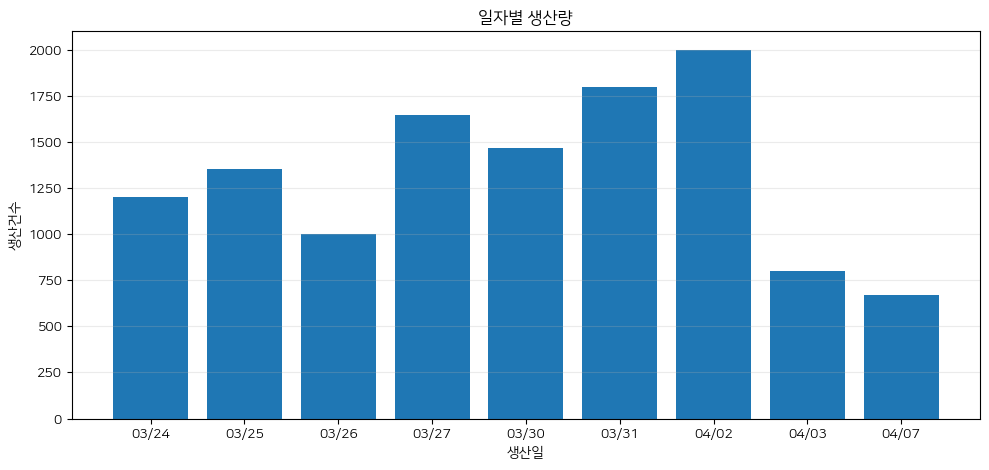

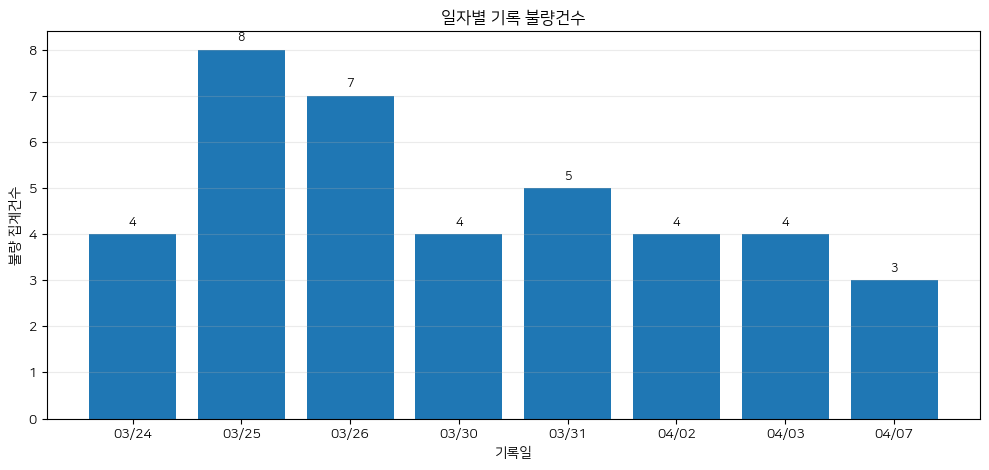

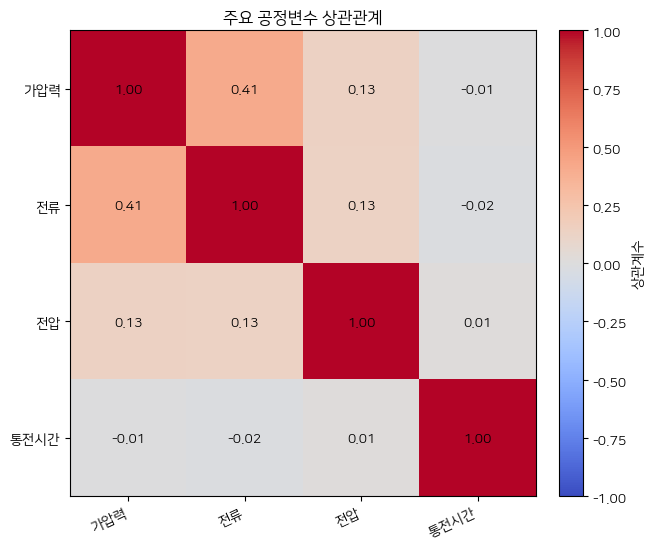

Figures saved to: /home/kampuser/project_final/source_code/source_code/outputs/eda_report/figures


In [11]:
# 그림 1. 일자별 생산량
plot_daily = production_daily.copy()
plt.figure(figsize=(10, 4.8))
plt.bar(plot_daily["date"].dt.strftime("%m/%d"), plot_daily["생산건수"])
plt.ylabel("생산건수")
plt.xlabel("생산일")
plt.title("일자별 생산량")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_daily_production.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

# 그림 2. 일자별 기록 불량건수 (3/27은 정답 미확인이라 표시하지 않음)
plot_defect = defect_daily.copy()
plt.figure(figsize=(10, 4.8))
plt.bar(plot_defect["date"].dt.strftime("%m/%d"), plot_defect["불량집계건수"])
for x, y in zip(plot_defect["date"].dt.strftime("%m/%d"), plot_defect["불량집계건수"]):
    plt.text(x, y + 0.12, str(int(y)), ha="center", va="bottom", fontsize=9)
plt.ylabel("불량 집계건수")
plt.xlabel("기록일")
plt.title("일자별 기록 불량건수")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_02_daily_defect_count.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

# 그림 3. 4개 공정변수 상관계수
corr = raw[FEATURES].corr()
labels = [FEATURE_KO[f] for f in FEATURES]
plt.figure(figsize=(6.8, 5.6))
im = plt.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(labels)), labels, rotation=25, ha="right")
plt.yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=10)
plt.colorbar(im, fraction=0.046, pad=0.04, label="상관계수")
plt.title("주요 공정변수 상관관계")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_03_feature_correlation.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

print("Figures saved to:", FIG_DIR.resolve())


## 12. 출력 파일 목록

In [12]:
print("\n[PPT/Word 표 PNG]")
for p in sorted(TABLE_DIR.glob("*.png")):
    print(" -", p)

print("\n[검증용 CSV]")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p)

print("\n[EDA 그림]")
for p in sorted(FIG_DIR.glob("*.png")):
    print(" -", p)



[PPT/Word 표 PNG]
 - outputs/eda_report/tables/table_01_dataset_overview.png
 - outputs/eda_report/tables/table_02_variable_definition.png
 - outputs/eda_report/tables/table_03_data_quality.png
 - outputs/eda_report/tables/table_04_daily_production_defect.png
 - outputs/eda_report/tables/table_05_process_descriptive_stats.png
 - outputs/eda_report/tables/table_07_defect_type_summary.png
 - outputs/eda_report/tables/table_08_eda_key_findings.png

[검증용 CSV]
 - outputs/eda_report/tables/table_01_dataset_overview.csv
 - outputs/eda_report/tables/table_02_variable_definition.csv
 - outputs/eda_report/tables/table_03_data_quality.csv
 - outputs/eda_report/tables/table_04_daily_production_defect.csv
 - outputs/eda_report/tables/table_05_process_descriptive_stats.csv
 - outputs/eda_report/tables/table_07_defect_type_summary.csv
 - outputs/eda_report/tables/table_08_eda_key_findings.csv

[EDA 그림]
 - outputs/eda_report/figures/fig_01_daily_production.png
 - outputs/eda_report/figures/fig_02_dail